# 2. Image Features and Similarity

Practice for module 2: image mass and center (moments), histograms, gradients and
histogram of gradients, and similarity metrics (L1, L2, cosine, cross-entropy).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

## 2.1 Test images

Two simple synthetic grayscale images: a bright square off-center and a diagonal stripe.

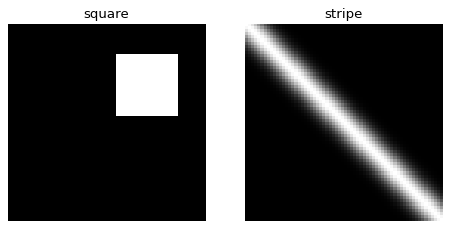

In [2]:
N = 64
yy, xx = np.mgrid[0:N, 0:N]

square = np.zeros((N, N)); square[10:30, 35:55] = 1.0
stripe = np.exp(-((xx - yy) ** 2) / (2 * 4.0 ** 2))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, im, t in zip(axes, [square, stripe], ["square", "stripe"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

## 2.2 Mass, center (first moment) and spread (second moment)

- mass = Σ I(x, y)
- center = intensity-weighted mean of coordinates
- second moment = spread of intensity around the center

square  mass=  400.0  center=( 44.5,  19.5)  spread=(  33.2,   33.2)
stripe  mass=  609.9  center=( 31.5,  31.5)  spread=( 313.5,  313.5)


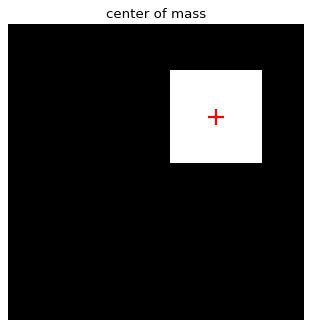

In [3]:
def moments(img):
    mass = img.sum()
    yy, xx = np.indices(img.shape)
    xc = (xx * img).sum() / mass
    yc = (yy * img).sum() / mass
    var_x = (((xx - xc) ** 2) * img).sum() / mass
    var_y = (((yy - yc) ** 2) * img).sum() / mass
    return mass, (xc, yc), (var_x, var_y)

for name, im in [("square", square), ("stripe", stripe)]:
    mass, (xc, yc), (vx, vy) = moments(im)
    print(f"{name:7s} mass={mass:7.1f}  center=({xc:5.1f}, {yc:5.1f})  spread=({vx:6.1f}, {vy:6.1f})")

mass, (xc, yc), _ = moments(square)
plt.imshow(square, cmap="gray"); plt.plot(xc, yc, "r+", ms=15, mew=2); plt.title("center of mass"); plt.axis("off")
plt.show()

## 2.3 Histogram as a feature vector

Range → number of bins → quantize → count. The histogram vector is what we compare later.

square: [3696.    0.    0.    0.    0.    0.    0.  400.]
stripe: [3080.  226.  116.  118.  120.    0.  122.  314.]


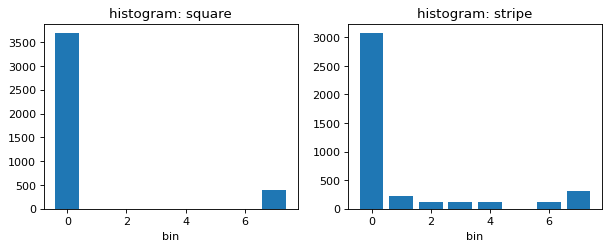

In [4]:
def histogram(img, bins=8, value_range=(0.0, 1.0)):
    lo, hi = value_range
    idx = np.clip(((img - lo) / (hi - lo) * bins).astype(int), 0, bins - 1)   # quantize
    return np.bincount(idx.ravel(), minlength=bins).astype(float)             # count per bin

h_square, h_stripe = histogram(square), histogram(stripe)
print("square:", h_square)
print("stripe:", h_stripe)
assert np.allclose(h_stripe, np.histogram(stripe, bins=8, range=(0, 1))[0])

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, h, t in zip(axes, [h_square, h_stripe], ["square", "stripe"]):
    ax.bar(range(8), h); ax.set_title(f"histogram: {t}"); ax.set_xlabel("bin")
plt.show()

## 2.4 Gradients

Forward differences: `Gx = f(x+1, y) - f(x, y)`, `Gy = f(x, y+1) - f(x, y)`;
then `magnitude = sqrt(Gx² + Gy²)`, `angle = atan2(Gy, Gx)`. Large magnitude = edge.

quiz check: Gx=3, Gy=4 -> magnitude 5.0


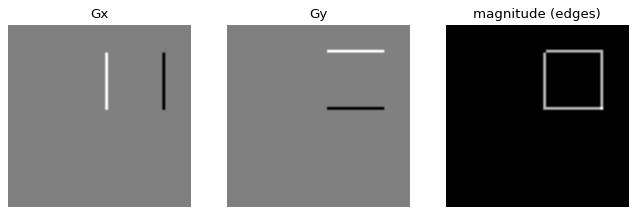

In [5]:
def gradients(img):
    gx = np.zeros_like(img); gy = np.zeros_like(img)
    gx[:, :-1] = img[:, 1:] - img[:, :-1]
    gy[:-1, :] = img[1:, :] - img[:-1, :]
    return gx, gy, np.hypot(gx, gy), np.arctan2(gy, gx)

print("quiz check: Gx=3, Gy=4 -> magnitude", np.hypot(3, 4))

gx, gy, mag, ang = gradients(square)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, im, t in zip(axes, [gx, gy, mag], ["Gx", "Gy", "magnitude (edges)"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

## 2.5 Histogram of gradients (orientation)

Angles weighted by magnitude: describes the dominant directions in the image.

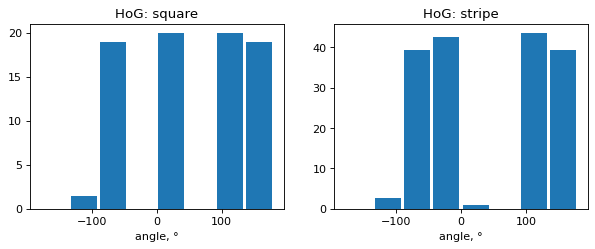

In [6]:
def hog(img, bins=8):
    _, _, mag, ang = gradients(img)
    h, _ = np.histogram(ang, bins=bins, range=(-np.pi, np.pi), weights=mag)
    return h

centers = np.linspace(-180, 180, 8, endpoint=False) + 22.5
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, im, t in zip(axes, [square, stripe], ["square", "stripe"]):
    ax.bar(centers, hog(im), width=40); ax.set_title(f"HoG: {t}"); ax.set_xlabel("angle, °")
plt.show()

## 2.6 Similarity metrics

Implemented by hand and checked against the quiz examples.

In [7]:
def l1(a, b):  return np.abs(np.asarray(a) - np.asarray(b)).sum()
def l2(a, b):  return np.sqrt(((np.asarray(a) - np.asarray(b)) ** 2).sum())
def l2_normalize(v):
    v = np.asarray(v, dtype=float); return v / np.linalg.norm(v)
def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
def cross_entropy(p, q, eps=1e-12):
    p, q = np.asarray(p, float), np.asarray(q, float)
    return -(p * np.log(q + eps)).sum()

print("L1((3,5),(1,9))        =", l1((3, 5), (1, 9)))
print("L2 with diffs 3 and 4  =", l2((3, 4), (0, 0)))
print("L2-normalize (3,4)     =", l2_normalize((3, 4)))
print("cos((1,0),(1,1))       =", round(cosine((1, 0), (1, 1)), 3))
print("H((1,0),(0.5,0.5))     =", round(cross_entropy((1, 0), (0.5, 0.5)), 3))
print("L1 == L2 for (0,0),(3,0):", l1((0, 0), (3, 0)), l2((0, 0), (3, 0)))

L1((3,5),(1,9))        = 6
L2 with diffs 3 and 4  = 5.0
L2-normalize (3,4)     = [0.6 0.8]
cos((1,0),(1,1))       = 0.707
H((1,0),(0.5,0.5))     = 0.693
L1 == L2 for (0,0),(3,0): 3 3.0


## 2.7 Unit "balls": L1 is a diamond, L2 is a circle

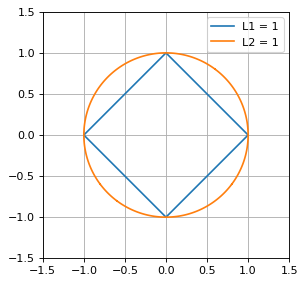

In [8]:
g = np.linspace(-1.5, 1.5, 301)
X, Y = np.meshgrid(g, g)
fig, ax = plt.subplots(figsize=(4, 4))
ax.contour(X, Y, np.abs(X) + np.abs(Y), levels=[1], colors="C0")
ax.contour(X, Y, np.hypot(X, Y), levels=[1], colors="C1")
ax.plot([], [], "C0", label="L1 = 1"); ax.plot([], [], "C1", label="L2 = 1")
ax.set_aspect("equal"); ax.grid(True); ax.legend()
plt.show()

## 2.8 Comparing images by their histograms

Normalize histograms to probability distributions (non-negative, sum to 1) and compare.
A histogram ignores *where* pixels are: the shifted square has exactly the same histogram (distance 0).
A noisy square is close, the stripe is far. Note that cross-entropy of a distribution with itself equals its entropy, not 0.

In [9]:
shifted = np.roll(square, 5, axis=1)
noisy = np.clip(square + np.random.default_rng(0).normal(0, 0.08, square.shape), 0, 1)
images = {"square": square, "shifted square": shifted, "noisy square": noisy, "stripe": stripe}
H = {k: histogram(v) / histogram(v).sum() for k, v in images.items()}

ref = H["square"]
print(f"{'vs square':16s} {'L1':>6s} {'L2':>6s} {'cosine':>7s} {'x-entropy':>10s}")
for name, h in H.items():
    print(f"{name:16s} {l1(ref, h):6.3f} {l2(ref, h):6.3f} {cosine(ref, h):7.3f} {cross_entropy(ref, h):10.3f}")

vs square            L1     L2  cosine  x-entropy
square            0.000  0.000   1.000      0.320
shifted square    0.000  0.000   1.000      0.320
noisy square      0.123  0.079   0.998      0.383
stripe            0.343  0.172   0.994      0.508


## Summary

- Moments: mass, center (1st), spread (2nd).
- Histograms and HoG turn images into vectors.
- Gradients find edges; magnitude `sqrt(Gx² + Gy²)`.
- L1 / L2 measure distance, cosine measures direction, cross-entropy compares distributions.